In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

In [ ]:
files=files.upload()

Saving iris.csv to iris.csv


In [ ]:
df=pd.read_csv('iris.csv')

In [ ]:
df.shape

(150, 5)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [ ]:

df['species'].unique()

array(['setosa', 'versicolor', 'virginica'], dtype=object)

In [ ]:

X=df.drop('species',axis=1)
y=df['species']

In [ ]:


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=101)

In [ ]:
scaler=StandardScaler()

In [ ]:
X_scaled_tr=scaler.fit_transform(X_train)
X_scaled_tst=scaler.transform(X_test)

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:


param_grid = {'C':[0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
              'penalty':['l1','l2'],
              'solver':['liblinear','saga']}


In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:

log = LogisticRegression(multi_class='multinomial',max_iter=5000)

In [ ]:

grid=GridSearchCV(log,param_grid,cv=5,scoring='accuracy',n_jobs=1)

In [ ]:
grid.fit(X_scaled_tr, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

GridSearchCV(cv=5,
             estimator=LogisticRegression(max_iter=5000,
                                          multi_class='multinomial'),
             n_jobs=1,
             param_grid={'C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
                         'penalty': ['l1', 'l2'],
                         'solver': ['liblinear', 'saga']},
             scoring='accuracy')

In [ ]:

print(grid.best_params_)

{'C': 1, 'penalty': 'l1', 'solver': 'saga'}


In [ ]:
log_model=LogisticRegression(multi_class='multinomial',max_iter=5000,C=1,penalty='l1',solver='saga')

In [ ]:
log_model.fit(X_scaled_tr,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(C=1, max_iter=5000, multi_class='multinomial', penalty='l1',
                   solver='saga')

In [ ]:
prediction=log_model.predict(X_scaled_tst)
prediction

array(['setosa', 'setosa', 'setosa', 'virginica', 'versicolor',
       'virginica', 'versicolor', 'versicolor', 'virginica', 'setosa',
       'virginica', 'setosa', 'setosa', 'virginica', 'virginica',
       'versicolor', 'versicolor', 'versicolor', 'setosa', 'versicolor',
       'versicolor', 'setosa', 'versicolor', 'versicolor', 'versicolor',
       'versicolor', 'versicolor', 'virginica', 'setosa', 'setosa',
       'virginica', 'versicolor', 'virginica', 'versicolor', 'virginica',
       'versicolor', 'versicolor', 'versicolor', 'versicolor',
       'virginica', 'setosa', 'setosa', 'setosa', 'virginica',
       'versicolor'], dtype=object)

In [ ]:
log_model.score(X_scaled_tst,y_test)

0.9555555555555556

In [ ]:
from sklearn.metrics import classification_report,confusion_matrix

In [ ]:
print(classification_report(y_test,prediction))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        13
  versicolor       0.95      0.95      0.95        20
   virginica       0.92      0.92      0.92        12

    accuracy                           0.96        45
   macro avg       0.96      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



In [ ]:
confusion_matrix(y_test,prediction)

array([[13,  0,  0],
       [ 0, 19,  1],
       [ 0,  1, 11]])

In [ ]:
cm=confusion_matrix(y_test,prediction)

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

In [ ]:
unique_labels=df['species'].unique()

In [ ]:
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=unique_labels)

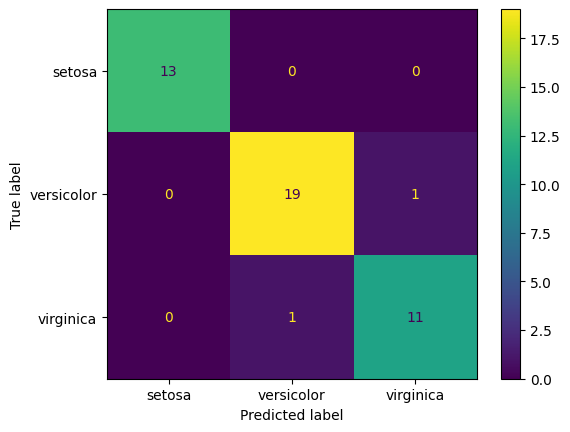

In [ ]:
disp.plot();